In [3]:
import itertools
from itertools import product

## EJEMPLO. Lanzamiento de un dado honesto 2 veces

Sea el experimento leatorio lanzar un dado honesto 2 veces, entonces sabemos que el espacio muestral es de la siguiente forma

$$ \Omega = \{ (i,j) \mid i,j\in\{1,2,3,4,5,6 \} \} $$

y además $|\Omega| = 6^2 = 36 $.

In [4]:
## Vamos a dividir el espacio muestral del lanzamiento de dos dados 

Omega = set(product([1,2,3,4,5,6], repeat = 2))
Omega

{(1, 1),
 (1, 2),
 (1, 3),
 (1, 4),
 (1, 5),
 (1, 6),
 (2, 1),
 (2, 2),
 (2, 3),
 (2, 4),
 (2, 5),
 (2, 6),
 (3, 1),
 (3, 2),
 (3, 3),
 (3, 4),
 (3, 5),
 (3, 6),
 (4, 1),
 (4, 2),
 (4, 3),
 (4, 4),
 (4, 5),
 (4, 6),
 (5, 1),
 (5, 2),
 (5, 3),
 (5, 4),
 (5, 5),
 (5, 6),
 (6, 1),
 (6, 2),
 (6, 3),
 (6, 4),
 (6, 5),
 (6, 6)}

Definimos el evento

- $S_n$: la suma de dos dados es $n$

donde $n\in\{2,3,\dots,12\}$


$$ S_n = \{ (i,j)\in\Omega \mid i+j = n\}$$

In [5]:
##Definimos Sn

def S(n):
    ##range genera una secuencia de numeros enteros del 1 al 6 
    Sn = { (i,j) for i in range(1,7) for j in range(1,7) if i+j == n}
    return Sn

In [6]:
## Por ejemplo si quiero que la suma de los dados sea 9

S_nueve =S(9)
S_nueve

{(3, 6), (4, 5), (5, 4), (6, 3)}

In [7]:
## Por ejemplo si quiero que la suma de los dados sea 5

S_cinco =S(5)
S_cinco

{(1, 4), (2, 3), (3, 2), (4, 1)}

In [8]:
## Voy a trabajar con fracciones 

from fractions import Fraction

In [9]:
##funcion de probabilidad
def P(A):
    P = Fraction(len(A), len(Omega))
    return P

Vamos a agrupar combinaciones por suma y para esto vamos a usar `defaultdict(set)` para crear un diccionario cuyas claves tengan como valor un conjunto vacio por defecto.

**Nota.** Es utili cuando queremos agupar resultados sin tener que verificar primero si la llave existe en el diccionario . {key : valor}

In [10]:
## Vamos a crear a Sn
## Asociando a cada par de numeros la suma de ambos numeros
Sn = { (i,j) : i+j for i,j in Omega }

In [11]:
## Agrupamos por sumas 
from collections import defaultdict

## Recorrer y agrupar por sumas

dsn= defaultdict(set)


In [12]:
## Vamos a recorrer los elementos del diccionario y agruparlos: llaves y valores
# i : es la llave, es el par ordenado 
# j : es el valor, es la suma de los elementos 
for i, j in Sn.items():
    dsn[j].add(i)  ## agregar el par ordenado a la suma correspondiente

In [13]:
## Vamos a visualizar la lista 

list(dsn.items())

[(7, {(1, 6), (2, 5), (3, 4), (4, 3), (5, 2), (6, 1)}),
 (4, {(1, 3), (2, 2), (3, 1)}),
 (9, {(3, 6), (4, 5), (5, 4), (6, 3)}),
 (10, {(4, 6), (5, 5), (6, 4)}),
 (6, {(1, 5), (2, 4), (3, 3), (4, 2), (5, 1)}),
 (8, {(2, 6), (3, 5), (4, 4), (5, 3), (6, 2)}),
 (11, {(5, 6), (6, 5)}),
 (3, {(1, 2), (2, 1)}),
 (5, {(1, 4), (2, 3), (3, 2), (4, 1)}),
 (2, {(1, 1)}),
 (12, {(6, 6)})]

Tenemos que una variable aleatoria $X$ es una funcion 

$$X : \Omega \to \mathbb{R} $$

La ley de una variable aleatoria discreta ( que toma valores sobre algun confunto discreto  

$\subseteq \mathbb{Z}$, y se define como sigue

$$ p_X(x) = \begin{cases} 
            \mathbb{P}(X=x), \quad \text{ si} x\in R_x \\
            0, \quad \text{en otro caso (e.o.c)}
            \\ \end{cases}$$

donde $R_X$ es el rango de la variable aleatoria $X$.

La funcion de densidad, cumple las siguientes propiedades:

- 1. $0 \leq p_X(k) \leq 1 $.
  2. $\sum_{k\in R_X} p_X(k) = 1$.

Para nuestro ejemplo, se tiene la siguiente v.a

$$ S_n : \Omega \to \{ 2,3,\dot,12 \}$$

In [14]:
## Vamos a crear la ley de Sn, que simplemento será la probabilidad de cada suma
LeySn = {i : P(A) for i,A in dsn.items()} #A representa al conjunto de pares ordenados que suman i
LeySn


{7: Fraction(1, 6),
 4: Fraction(1, 12),
 9: Fraction(1, 9),
 10: Fraction(1, 12),
 6: Fraction(5, 36),
 8: Fraction(5, 36),
 11: Fraction(1, 18),
 3: Fraction(1, 18),
 5: Fraction(1, 9),
 2: Fraction(1, 36),
 12: Fraction(1, 36)}

Vamos a visualizar la libreria ´pandas´ que se usa para manipular y anallizar datos


In [15]:

import pandas as pd

Vamos a usar 'pd.Series()' para convertir el diccionaro 'LeySn' en una serie de pandas

In [16]:
Ley_Sn =pd.Series(LeySn)
Ley_Sn

7      1/6
4     1/12
9      1/9
10    1/12
6     5/36
8     5/36
11    1/18
3     1/18
5      1/9
2     1/36
12    1/36
dtype: object

In [22]:
## Ordeno de manera ascendente
Ley_Sn = Ley_Sn.sort_index()
Ley_Sn

2     1/36
3     1/18
4     1/12
5      1/9
6     5/36
7      1/6
8     5/36
9      1/9
10    1/12
11    1/18
12    1/36
dtype: object

In [29]:
# Vamos a definir la función de densidad (ley de Sn)
import numpy as np

def LeyS(i):
    if i in range(2,13): # es de 2 hasta 12
        x = LeySn[i] # me asigne probabilidad
    else:
        x = 0 # no me asigne probabilidad
    return x  
    

In [30]:
# Creamos el rango de la v.a. 
rango_S = [k for k in range(2,13)]

# Obtenemos la probabilidad de cada suma en el rango de S
p_k = [float(LeyS(k)) for k in rango_S]
p_k

[0.027777777777777776,
 0.05555555555555555,
 0.08333333333333333,
 0.1111111111111111,
 0.1388888888888889,
 0.16666666666666666,
 0.1388888888888889,
 0.1111111111111111,
 0.08333333333333333,
 0.05555555555555555,
 0.027777777777777776]

In [31]:
# Se puede verificar que la suma es 1.
sum(p_k)

1.0

Vamos a crear un DataFrame, donde los valores del rango de S (`rango_S`) y `p_k` son las probabilidades de cada suma.

In [33]:
lS = pd.DataFrame(list(zip(rango_S, p_k)),
                  index = [f'S_{k}' for k in rango_S],
                  columns = ['rango','densidad'])
lS

,rango,densidad
S_2,2,0.027778
S_3,3,0.055556
S_4,4,0.083333
S_5,5,0.111111
S_6,6,0.138889
S_7,7,0.166667
S_8,8,0.138889
S_9,9,0.111111
S_10,10,0.083333
S_11,11,0.055556


<Axes: xlabel='rango'>

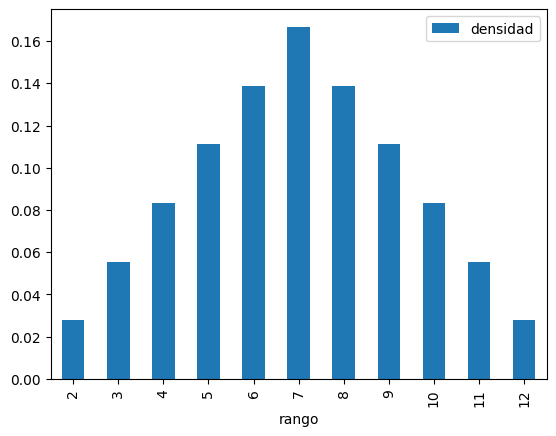

In [34]:
lS.plot.bar( x = 'rango', y = 'densidad')